In [3]:
# Import Library
import os
import tensorflow as tf
import numpy as np
import pandas as pd

from tqdm.auto import tqdm

print("TensorFlow version:", tf.__version__)
print("Python environment siap.")

2026-11-18 22:24:15.675616: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-18 22:24:16.401616: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-18 22:24:16.401923: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-18 22:24:16.551828: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-18 22:24:16.854960: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-18 22:24:16.858809: I tensorflow/core/platform/cpu_feature_guard.cc:1

TensorFlow version: 2.15.1
Python environment siap.


/home/rzangef/SSD-PPE/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Konfigurasi Model
import sys

RESEARCH_PATH = (
    "/home/rzangef/SSD-PPE/"
    "object-detection-api/research"
)

if RESEARCH_PATH not in sys.path:
    sys.path.insert(0, RESEARCH_PATH)

from object_detection.utils import config_util
from object_detection.builders import model_builder

CONFIG_PATH = (
    "/home/rzangef/SSD-PPE/models/"
    "pipeline_ppe_yolo_split_stage5.config"
)

CHECKPOINT_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/"
    "ckpt-7"
)

print("Config tersedia:", os.path.exists(CONFIG_PATH))
print("Checkpoint tersedia:",
      os.path.exists(CHECKPOINT_6000 + ".index"))

Config tersedia: True
Checkpoint tersedia: True


In [5]:
# Membangun Model SSD MobileNet
configs = config_util.get_configs_from_pipeline_file(
    CONFIG_PATH
)

model_config = configs["model"]

detection_model = model_builder.build(
    model_config=model_config,
    is_training=False
)

print("Model SSD MobileNet berhasil dibangun.")

# Memuat Checkpoint 6.000 Step
status = tf.train.Checkpoint(
    model=detection_model
).restore(CHECKPOINT_6000)

status.expect_partial()
status.assert_existing_objects_matched()

print("Checkpoint 6.000 step berhasil dimuat.")

Model SSD MobileNet berhasil dibangun.
Checkpoint 6.000 step berhasil dimuat.


In [1]:
# TAHAP 1 : Membandingkan kedua checkpoint pada validation set

In [6]:
# Muat kembali checkpoint 6000
CHECKPOINT_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/"
    "ckpt-7"
)

print("Checkpoint:", CHECKPOINT_6000)

status = tf.train.Checkpoint(
    model=detection_model
).restore(CHECKPOINT_6000)

status.expect_partial()
status.assert_existing_objects_matched()

print("Checkpoint 6.000 step berhasil dimuat.")

Checkpoint: /home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_yolo_split/ckpt-7
Checkpoint 6.000 step berhasil dimuat.


In [7]:
# Evaluasi ulang 6000 step pada data validasi
import tensorflow as tf
import numpy as np
import pandas as pd
import time

VAL_RECORD = (
    "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/val.record"
)

FEATURES = {
    "image/encoded": tf.io.FixedLenFeature([], tf.string),
    "image/filename": tf.io.FixedLenFeature([], tf.string, default_value=b""),
    "image/object/bbox/xmin": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/xmax": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/ymin": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/ymax": tf.io.VarLenFeature(tf.float32),
    "image/object/class/label": tf.io.VarLenFeature(tf.int64),
}

def sparse_array(example, key, dtype):
    return tf.sparse.to_dense(example[key]).numpy().astype(dtype)

def calculate_iou(box, boxes):
    # Format box: [ymin, xmin, ymax, xmax]
    if len(boxes) == 0:
        return np.array([], dtype=np.float32)

    y1 = np.maximum(box[0], boxes[:, 0])
    x1 = np.maximum(box[1], boxes[:, 1])
    y2 = np.minimum(box[2], boxes[:, 2])
    x2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, y2-y1) * np.maximum(0, x2-x1)

    area_box = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    area_boxes = (
        np.maximum(0, boxes[:, 2]-boxes[:, 0]) *
        np.maximum(0, boxes[:, 3]-boxes[:, 1])
    )

    union = area_box + area_boxes - intersection
    return intersection / np.maximum(union, 1e-9)

# Simpan hasil inferensi agar model hanya dijalankan sekali per gambar.
records = []
total_gt = 0
start_time = time.time()

dataset = tf.data.TFRecordDataset(VAL_RECORD)

for image_index, raw in enumerate(dataset):
    example = tf.io.parse_single_example(raw, FEATURES)

    image = tf.io.decode_image(
        example["image/encoded"],
        channels=3,
        expand_animations=False
    )
    image = tf.cast(image, tf.float32)[tf.newaxis, ...]

    preprocessed, shapes = detection_model.preprocess(image)
    prediction = detection_model.predict(preprocessed, shapes)
    detections = detection_model.postprocess(prediction, shapes)

    n = int(detections["num_detections"][0].numpy())

    pred_boxes = detections["detection_boxes"][0].numpy()[:n]
    pred_scores = detections["detection_scores"][0].numpy()[:n]

    # NMS mengembalikan ID foreground mulai dari 0.
    pred_classes = (
        detections["detection_classes"][0].numpy()[:n].astype(int) + 1
    )

    gt_labels = sparse_array(
        example, "image/object/class/label", np.int32
    )
    xmin = sparse_array(example, "image/object/bbox/xmin", np.float32)
    xmax = sparse_array(example, "image/object/bbox/xmax", np.float32)
    ymin = sparse_array(example, "image/object/bbox/ymin", np.float32)
    ymax = sparse_array(example, "image/object/bbox/ymax", np.float32)

    # Ground truth diubah ke format [ymin, xmin, ymax, xmax].
    gt_boxes = np.column_stack([ymin, xmin, ymax, xmax]).astype(np.float32)

    if not (
        len(gt_labels) == len(gt_boxes)
        == len(xmin) == len(xmax) == len(ymin) == len(ymax)
    ):
        raise ValueError(f"Jumlah anotasi tidak cocok pada gambar {image_index}")

    records.append({
        "pred_boxes": pred_boxes,
        "pred_scores": pred_scores,
        "pred_classes": pred_classes,
        "gt_boxes": gt_boxes,
        "gt_classes": gt_labels,
    })

    total_gt += len(gt_labels)

    if (image_index + 1) % 25 == 0:
        print(f"Sudah diproses: {image_index + 1} gambar")

print("\n=== INFERENSI VALIDASI SELESAI ===")
print("Jumlah gambar:", len(records))
print("Jumlah ground truth:", total_gt)
print(f"Waktu inferensi: {(time.time()-start_time)/60:.1f} menit")

# Evaluasi ulang hasil inferensi pada berbagai confidence threshold.
confidence_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.50
]
IOU_THRESHOLD = 0.50

results = []

for conf_threshold in confidence_thresholds:
    TP = FP = FN = 0

    for rec in records:
        gt_boxes = rec["gt_boxes"]
        gt_classes = rec["gt_classes"]

        keep = rec["pred_scores"] >= conf_threshold
        boxes = rec["pred_boxes"][keep]
        scores = rec["pred_scores"][keep]
        classes = rec["pred_classes"][keep]

        # Urutkan prediksi dari confidence tertinggi.
        order = np.argsort(-scores)
        boxes = boxes[order]
        classes = classes[order]

        matched_gt = set()
        image_tp = 0

        for box, pred_class in zip(boxes, classes):
            # Hanya GT dengan kelas yang sama yang dapat dicocokkan.
            candidate_indices = [
                j for j, gt_class in enumerate(gt_classes)
                if gt_class == pred_class and j not in matched_gt
            ]

            if not candidate_indices:
                continue

            candidate_boxes = gt_boxes[candidate_indices]
            ious = calculate_iou(box, candidate_boxes)
            best_pos = int(np.argmax(ious))

            if ious[best_pos] >= IOU_THRESHOLD:
                matched_gt.add(candidate_indices[best_pos])
                image_tp += 1

        TP += image_tp
        FP += len(boxes) - image_tp
        FN += len(gt_boxes) - image_tp

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    results.append({
        "Confidence": conf_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
    })

validation_results = pd.DataFrame(results)

print("\n=== HASIL EVALUASI DATA VALIDASI ===")
display(
    validation_results.style.format({
        "Confidence": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
    })
)

best_row = validation_results.loc[
    validation_results["F1-score"].idxmax()
]

print("\n=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===")
print("Confidence:", best_row["Confidence"])
print("Precision:", f"{best_row['Precision']:.4f}")
print("Recall:", f"{best_row['Recall']:.4f}")
print("F1-score:", f"{best_row['F1-score']:.4f}")
print("TP:", int(best_row["TP"]))
print("FP:", int(best_row["FP"]))
print("FN:", int(best_row["FN"]))

Sudah diproses: 25 gambar
Sudah diproses: 50 gambar
Sudah diproses: 75 gambar
Sudah diproses: 100 gambar
Sudah diproses: 125 gambar
Sudah diproses: 150 gambar

=== INFERENSI VALIDASI SELESAI ===
Jumlah gambar: 170
Jumlah ground truth: 1211
Waktu inferensi: 1.8 menit

=== HASIL EVALUASI DATA VALIDASI ===


AttributeError: The '.style' accessor requires jinja2

In [8]:
# Atasi eror jinja2
# Tampilkan hasil evaluasi tanpa menggunakan .style
print("=== HASIL EVALUASI DATA VALIDASI ===")
display(validation_results)

# Ambil hasil dengan F1-score tertinggi
best_row = validation_results.loc[
    validation_results["F1-score"].idxmax()
]

print("\n=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===")
print("Confidence:", best_row["Confidence"])
print("Precision:", f'{best_row["Precision"]:.4f}')
print("Recall:", f'{best_row["Recall"]:.4f}')
print("F1-score:", f'{best_row["F1-score"]:.4f}')
print("TP:", int(best_row["TP"]))
print("FP:", int(best_row["FP"]))
print("FN:", int(best_row["FN"]))

=== HASIL EVALUASI DATA VALIDASI ===


,Confidence,TP,FP,FN,Precision,Recall,F1-score
0,0.05,794,16052,417,0.047133,0.655656,0.087944
1,0.10,778,12364,433,0.059200,0.642444,0.108409
2,0.15,724,7862,487,0.084323,0.597853,0.147800
3,0.20,638,4573,573,0.122433,0.526837,0.198692
4,0.25,570,2681,641,0.175331,0.470685,0.255491
5,0.30,490,1523,721,0.243418,0.404624,0.303970
6,0.35,397,872,814,0.312845,0.327828,0.320161
7,0.40,334,521,877,0.390643,0.275805,0.323330
8,0.50,212,207,999,0.505967,0.175062,0.260123



=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===
Confidence: 0.4
Precision: 0.3906
Recall: 0.2758
F1-score: 0.3233
TP: 334
FP: 521
FN: 877


In [9]:
# 10.000 steps

In [10]:
# Memuat Checkpoint SSD MobileNet 10.000 step
import os
import sys
import tensorflow as tf

# Lokasi Object Detection API
RESEARCH_PATH = "/home/rzangef/SSD-PPE/object-detection-api/research"

if RESEARCH_PATH not in sys.path:
    sys.path.insert(0, RESEARCH_PATH)

from object_detection.utils import config_util
from object_detection.builders import model_builder

# Lokasi konfigurasi 10.000 step
CONFIG_PATH = (
    "/home/rzangef/SSD-PPE/models/"
    "pipeline_ppe_yolo_split_continue_10000.config"
)

# Lokasi checkpoint 10.000 step
CHECKPOINT_PATH = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_continue_10000/"
    "ckpt-5"
)

# Memuat konfigurasi model
configs = config_util.get_configs_from_pipeline_file(CONFIG_PATH)
model_config = configs["model"]

# Membuat model baru
detection_model = model_builder.build(
    model_config=model_config,
    is_training=False
)

# Memuat bobot checkpoint
status = tf.train.Checkpoint(
    model=detection_model
).restore(CHECKPOINT_PATH)

status.expect_partial()
status.assert_existing_objects_matched()

print("Checkpoint 10.000 step berhasil dimuat.")

Checkpoint 10.000 step berhasil dimuat.


In [11]:
# Evaluasi ulang 10.000 step pada data validasi
import tensorflow as tf
import numpy as np
import pandas as pd
import time

VAL_RECORD = (
    "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/val.record"
)

FEATURES = {
    "image/encoded": tf.io.FixedLenFeature([], tf.string),
    "image/filename": tf.io.FixedLenFeature([], tf.string, default_value=b""),
    "image/object/bbox/xmin": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/xmax": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/ymin": tf.io.VarLenFeature(tf.float32),
    "image/object/bbox/ymax": tf.io.VarLenFeature(tf.float32),
    "image/object/class/label": tf.io.VarLenFeature(tf.int64),
}

def sparse_array(example, key, dtype):
    return tf.sparse.to_dense(example[key]).numpy().astype(dtype)

def calculate_iou(box, boxes):
    # Format box: [ymin, xmin, ymax, xmax]
    if len(boxes) == 0:
        return np.array([], dtype=np.float32)

    y1 = np.maximum(box[0], boxes[:, 0])
    x1 = np.maximum(box[1], boxes[:, 1])
    y2 = np.minimum(box[2], boxes[:, 2])
    x2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, y2-y1) * np.maximum(0, x2-x1)

    area_box = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    area_boxes = (
        np.maximum(0, boxes[:, 2]-boxes[:, 0]) *
        np.maximum(0, boxes[:, 3]-boxes[:, 1])
    )

    union = area_box + area_boxes - intersection
    return intersection / np.maximum(union, 1e-9)

# Simpan hasil inferensi agar model hanya dijalankan sekali per gambar.
records = []
total_gt = 0
start_time = time.time()

dataset = tf.data.TFRecordDataset(VAL_RECORD)

for image_index, raw in enumerate(dataset):
    example = tf.io.parse_single_example(raw, FEATURES)

    image = tf.io.decode_image(
        example["image/encoded"],
        channels=3,
        expand_animations=False
    )
    image = tf.cast(image, tf.float32)[tf.newaxis, ...]

    preprocessed, shapes = detection_model.preprocess(image)
    prediction = detection_model.predict(preprocessed, shapes)
    detections = detection_model.postprocess(prediction, shapes)

    n = int(detections["num_detections"][0].numpy())

    pred_boxes = detections["detection_boxes"][0].numpy()[:n]
    pred_scores = detections["detection_scores"][0].numpy()[:n]

    # NMS mengembalikan ID foreground mulai dari 0.
    pred_classes = (
        detections["detection_classes"][0].numpy()[:n].astype(int) + 1
    )

    gt_labels = sparse_array(
        example, "image/object/class/label", np.int32
    )
    xmin = sparse_array(example, "image/object/bbox/xmin", np.float32)
    xmax = sparse_array(example, "image/object/bbox/xmax", np.float32)
    ymin = sparse_array(example, "image/object/bbox/ymin", np.float32)
    ymax = sparse_array(example, "image/object/bbox/ymax", np.float32)

    # Ground truth diubah ke format [ymin, xmin, ymax, xmax].
    gt_boxes = np.column_stack([ymin, xmin, ymax, xmax]).astype(np.float32)

    if not (
        len(gt_labels) == len(gt_boxes)
        == len(xmin) == len(xmax) == len(ymin) == len(ymax)
    ):
        raise ValueError(f"Jumlah anotasi tidak cocok pada gambar {image_index}")

    records.append({
        "pred_boxes": pred_boxes,
        "pred_scores": pred_scores,
        "pred_classes": pred_classes,
        "gt_boxes": gt_boxes,
        "gt_classes": gt_labels,
    })

    total_gt += len(gt_labels)

    if (image_index + 1) % 25 == 0:
        print(f"Sudah diproses: {image_index + 1} gambar")

print("\n=== INFERENSI VALIDASI SELESAI ===")
print("Jumlah gambar:", len(records))
print("Jumlah ground truth:", total_gt)
print(f"Waktu inferensi: {(time.time()-start_time)/60:.1f} menit")

# Evaluasi ulang hasil inferensi pada berbagai confidence threshold.
confidence_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.50
]
IOU_THRESHOLD = 0.50

results = []

for conf_threshold in confidence_thresholds:
    TP = FP = FN = 0

    for rec in records:
        gt_boxes = rec["gt_boxes"]
        gt_classes = rec["gt_classes"]

        keep = rec["pred_scores"] >= conf_threshold
        boxes = rec["pred_boxes"][keep]
        scores = rec["pred_scores"][keep]
        classes = rec["pred_classes"][keep]

        # Urutkan prediksi dari confidence tertinggi.
        order = np.argsort(-scores)
        boxes = boxes[order]
        classes = classes[order]

        matched_gt = set()
        image_tp = 0

        for box, pred_class in zip(boxes, classes):
            # Hanya GT dengan kelas yang sama yang dapat dicocokkan.
            candidate_indices = [
                j for j, gt_class in enumerate(gt_classes)
                if gt_class == pred_class and j not in matched_gt
            ]

            if not candidate_indices:
                continue

            candidate_boxes = gt_boxes[candidate_indices]
            ious = calculate_iou(box, candidate_boxes)
            best_pos = int(np.argmax(ious))

            if ious[best_pos] >= IOU_THRESHOLD:
                matched_gt.add(candidate_indices[best_pos])
                image_tp += 1

        TP += image_tp
        FP += len(boxes) - image_tp
        FN += len(gt_boxes) - image_tp

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    results.append({
        "Confidence": conf_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
    })

validation_results = pd.DataFrame(results)

print("\n=== HASIL EVALUASI DATA VALIDASI ===")
display(
    validation_results.style.format({
        "Confidence": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
    })
)

best_row = validation_results.loc[
    validation_results["F1-score"].idxmax()
]

print("\n=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===")
print("Confidence:", best_row["Confidence"])
print("Precision:", f"{best_row['Precision']:.4f}")
print("Recall:", f"{best_row['Recall']:.4f}")
print("F1-score:", f"{best_row['F1-score']:.4f}")
print("TP:", int(best_row["TP"]))
print("FP:", int(best_row["FP"]))
print("FN:", int(best_row["FN"]))

Sudah diproses: 25 gambar
Sudah diproses: 50 gambar
Sudah diproses: 75 gambar
Sudah diproses: 100 gambar
Sudah diproses: 125 gambar
Sudah diproses: 150 gambar

=== INFERENSI VALIDASI SELESAI ===
Jumlah gambar: 170
Jumlah ground truth: 1211
Waktu inferensi: 1.6 menit

=== HASIL EVALUASI DATA VALIDASI ===


AttributeError: The '.style' accessor requires jinja2

In [12]:
# Atasi eror jinja2
# Tampilkan hasil evaluasi tanpa menggunakan .style
print("=== HASIL EVALUASI DATA VALIDASI ===")
display(validation_results)

# Ambil hasil dengan F1-score tertinggi
best_row = validation_results.loc[
    validation_results["F1-score"].idxmax()
]

print("\n=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===")
print("Confidence:", best_row["Confidence"])
print("Precision:", f'{best_row["Precision"]:.4f}')
print("Recall:", f'{best_row["Recall"]:.4f}')
print("F1-score:", f'{best_row["F1-score"]:.4f}')
print("TP:", int(best_row["TP"]))
print("FP:", int(best_row["FP"]))
print("FN:", int(best_row["FN"]))

=== HASIL EVALUASI DATA VALIDASI ===


,Confidence,TP,FP,FN,Precision,Recall,F1-score
0,0.05,445,11807,766,0.036321,0.367465,0.066107
1,0.10,366,6249,845,0.055329,0.302230,0.093534
2,0.15,301,3666,910,0.075876,0.248555,0.116261
3,0.20,253,2170,958,0.104416,0.208918,0.139241
4,0.25,188,1307,1023,0.125753,0.155244,0.138950
5,0.30,144,666,1067,0.177778,0.118910,0.142504
6,0.35,114,448,1097,0.202847,0.094137,0.128596
7,0.40,93,311,1118,0.230198,0.076796,0.115170
8,0.50,49,115,1162,0.298780,0.040462,0.071273



=== AMBANG CONFIDENCE TERBAIK PADA VALIDASI ===
Confidence: 0.3
Precision: 0.1778
Recall: 0.1189
F1-score: 0.1425
TP: 144
FP: 666
FN: 1067


In [13]:
# PERIKSA TRAINING LOSS

In [14]:
# Cari file log training
import os

FOLDER_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split"
)

FOLDER_10000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_continue_10000"
)

for nama, folder in [
    ("CHECKPOINT 6000 STEP", FOLDER_6000),
    ("CHECKPOINT 10000 STEP", FOLDER_10000)
]:
    print(f"\n=== {nama} ===")

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.startswith("events.out.tfevents"):
                print(os.path.join(root, file))


=== CHECKPOINT 6000 STEP ===
/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_yolo_split/train/events.out.tfevents.1792483187.LAPTOP-ODRK022O.4102.0.v2

=== CHECKPOINT 10000 STEP ===
/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_continue_10000/train/events.out.tfevents.1794467557.LAPTOP-ODRK022O.2750.0.v2


In [15]:
# Baca Training Loss
import tensorflow as tf
import pandas as pd
import os

LOG_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/"
    "train/events.out.tfevents.1792483187.LAPTOP-ODRK022O.4102.0.v2"
)

LOG_10000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_continue_10000/"
    "train/events.out.tfevents.1794467557.LAPTOP-ODRK022O.2750.0.v2"
)

def baca_training_loss(log_path):
    data = []

    for event in tf.compat.v1.train.summary_iterator(log_path):
        for value in event.summary.value:

            # Membaca nilai scalar
            if value.HasField("simple_value"):
                loss_value = value.simple_value

            elif value.HasField("tensor"):
                try:
                    loss_value = tf.make_ndarray(
                        value.tensor
                    ).item()
                except:
                    continue
            else:
                continue

            data.append({
                "Step": event.step,
                "Loss": value.tag,
                "Value": loss_value
            })

    return pd.DataFrame(data)


# Membaca kedua file log
loss_6000 = baca_training_loss(LOG_6000)
loss_10000 = baca_training_loss(LOG_10000)

print("=== TRAINING LOSS 6000 STEP ===")
display(loss_6000.tail(15))

print("\n=== TRAINING LOSS 10000 STEP ===")
display(loss_10000.tail(15))

print("\n=== TAG LOSS YANG TERSEDIA ===")
print("6000 step:", loss_6000["Loss"].unique())
print("10000 step:", loss_10000["Loss"].unique())

Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`


=== TRAINING LOSS 6000 STEP ===


,Step,Loss,Value
345,5800,Loss/regularization_loss,1.533556e-01
346,5800,Loss/total_loss,1.099371e+00
347,5800,learning_rate,4.712910e-07
348,5900,steps_per_sec,3.169400e+00
349,5900,Loss/localization_loss,3.468067e-01
350,5900,Loss/classification_loss,3.673975e-01
351,5900,Loss/regularization_loss,1.533556e-01
352,5900,Loss/total_loss,8.675599e-01
353,5900,learning_rate,4.540980e-08
354,6000,steps_per_sec,3.374934e+00



=== TRAINING LOSS 10000 STEP ===


,Step,Loss,Value
225,3800,Loss/regularization_loss,1.533203e-01
226,3800,Loss/total_loss,1.891605e+00
227,3800,learning_rate,6.819337e-07
228,3900,steps_per_sec,6.700902e+00
229,3900,Loss/localization_loss,5.882210e-01
230,3900,Loss/classification_loss,9.488857e-01
231,3900,Loss/regularization_loss,1.533203e-01
232,3900,Loss/total_loss,1.690427e+00
233,3900,learning_rate,1.707733e-07
234,4000,steps_per_sec,6.811626e+00



=== TAG LOSS YANG TERSEDIA ===
6000 step: ['steps_per_sec' 'Loss/localization_loss' 'Loss/classification_loss'
 'Loss/regularization_loss' 'Loss/total_loss' 'learning_rate']
10000 step: ['steps_per_sec' 'Loss/localization_loss' 'Loss/classification_loss'
 'Loss/regularization_loss' 'Loss/total_loss' 'learning_rate']


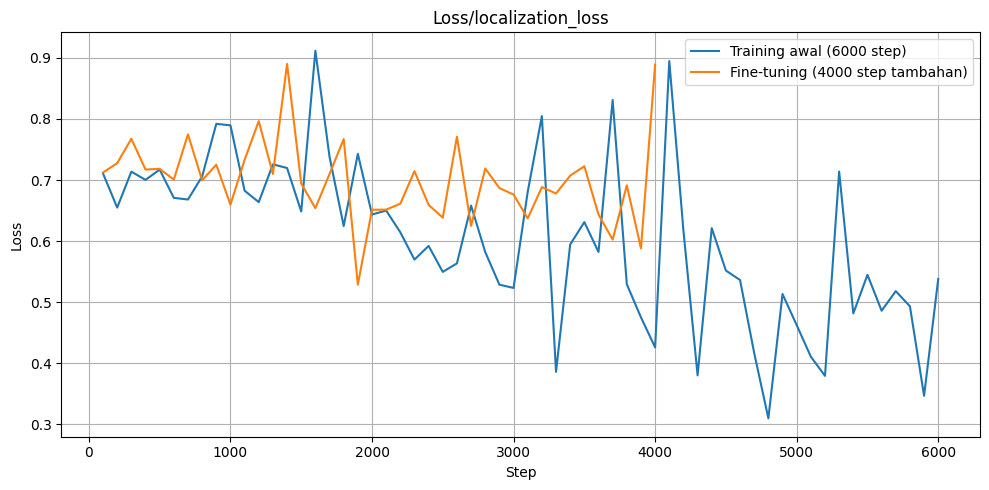

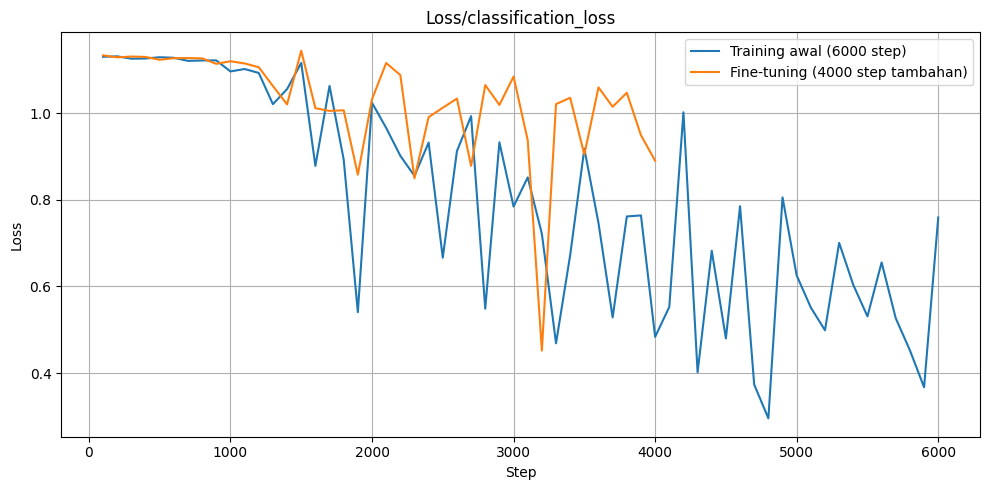

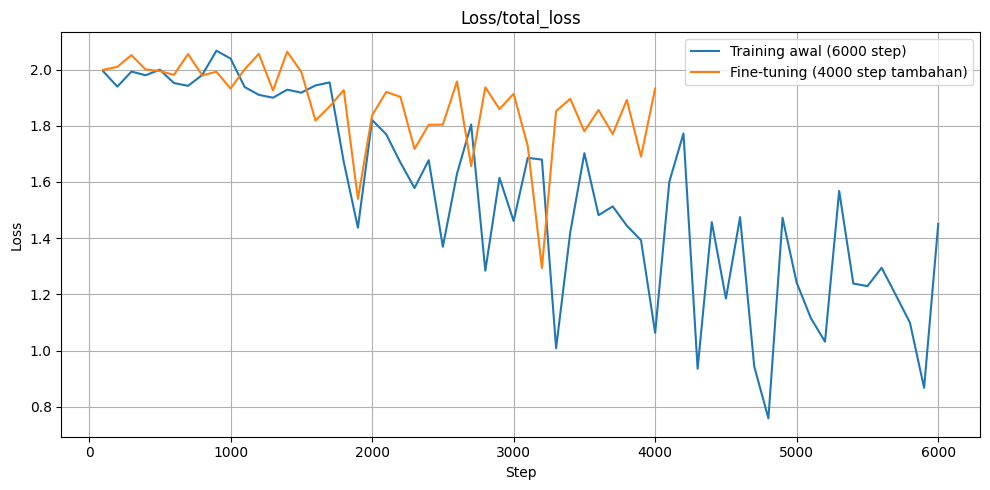

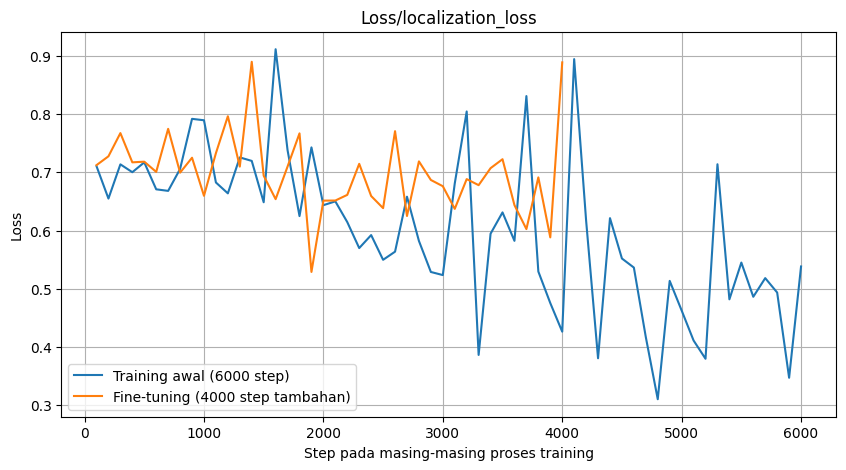

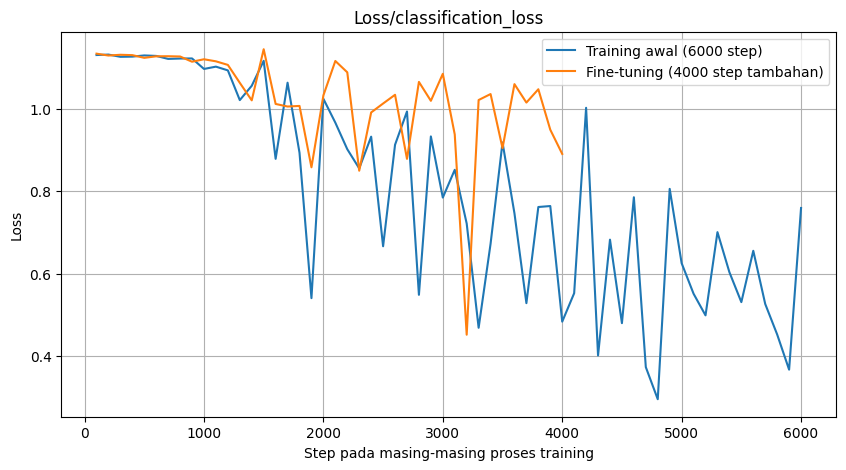

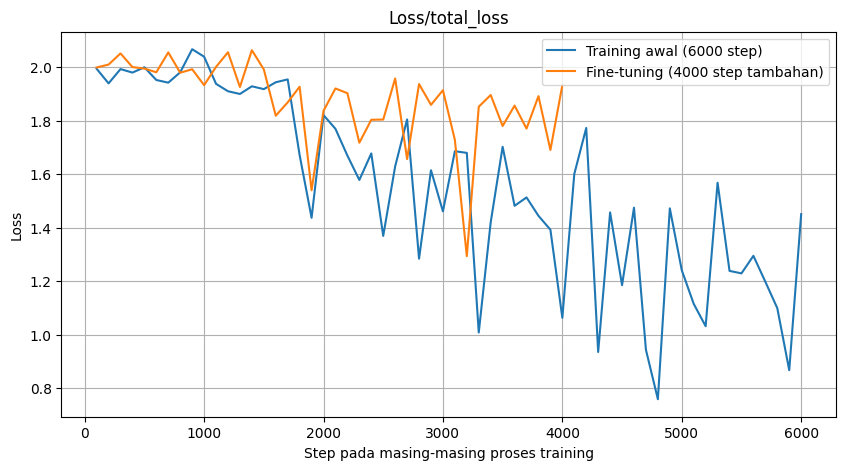

In [17]:
# Membuat Grafik Localization Loss, Classification Loss, Total Loss
%matplotlib inline

import matplotlib.pyplot as plt
from IPython.display import display

loss_tags = [
    "Loss/localization_loss",
    "Loss/classification_loss",
    "Loss/total_loss"
]

for tag in loss_tags:
    fig, ax = plt.subplots(figsize=(10, 5))

    data_6000 = loss_6000[loss_6000["Loss"] == tag]
    data_10000 = loss_10000[loss_10000["Loss"] == tag]

    ax.plot(
        data_6000["Step"],
        data_6000["Value"],
        label="Training awal (6000 step)"
    )

    ax.plot(
        data_10000["Step"],
        data_10000["Value"],
        label="Fine-tuning (4000 step tambahan)"
    )

    ax.set_title(tag)
    ax.set_xlabel("Step")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()
    display(fig)
    plt.close(fig)

In [18]:
# Periksa Konfigurasi Training
CONFIG_FILES = {
    "TRAINING AWAL 6000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_stage5.config"
    ),
    "FINE-TUNING 10000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_continue_10000.config"
    )
}

keywords = [
    "num_steps",
    "batch_size",
    "fine_tune_checkpoint",
    "fine_tune_checkpoint_type",
    "learning_rate",
    "initial_learning_rate",
    "decay_steps",
    "decay_factor",
    "warmup"
]

for nama, path in CONFIG_FILES.items():
    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    with open(path, "r") as file:
        lines = file.readlines()

    for i, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            print(f"Baris {i+1}: {line.rstrip()}")


TRAINING AWAL 6000 STEP
Baris 135:   batch_size: 1
Baris 153:       learning_rate {
Baris 154:         cosine_decay_learning_rate {
Baris 155:           learning_rate_base: 0.0003
Baris 157:           warmup_learning_rate: 0.0001
Baris 158:           warmup_steps: 200
Baris 165:   fine_tune_checkpoint: "/home/rzangef/SSD-PPE/models/ssd_mobilenet_v2_fpnlite_320x320/ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/ckpt-0"
Baris 166:   num_steps: 5945
Baris 171:   fine_tune_checkpoint_type: "detection"
Baris 172:   fine_tune_checkpoint_version: V2

FINE-TUNING 10000 STEP
Baris 135:   batch_size: 1
Baris 153:       learning_rate {
Baris 154:         cosine_decay_learning_rate {
Baris 155:           learning_rate_base: 0.0001
Baris 157:           warmup_learning_rate: 0.0001
Baris 158:           warmup_steps: 200
Baris 165:   fine_tune_checkpoint: "/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_yolo_split/ckpt-7"
Baris 166:   num_steps: 4000
Baris 171:   fine_tune_

In [19]:
# Cek konfigurasi learning rate
CONFIG_FILES = {
    "TRAINING AWAL 6000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_stage5.config"
    ),
    "FINE-TUNING 10000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_continue_10000.config"
    )
}

for nama, path in CONFIG_FILES.items():
    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    with open(path, "r") as file:
        lines = file.readlines()

    # Menampilkan baris 145 sampai 175
    for i in range(144, min(175, len(lines))):
        print(f"{i+1}: {lines[i].rstrip()}")


TRAINING AWAL 6000 STEP
145:       min_area: 0.75
146:       max_area: 1.0
147:       overlap_thresh: 0.0
148:     }
149:   }
150:   sync_replicas: true
151:   optimizer {
152:     momentum_optimizer {
153:       learning_rate {
154:         cosine_decay_learning_rate {
155:           learning_rate_base: 0.0003
156:           total_steps: 5945
157:           warmup_learning_rate: 0.0001
158:           warmup_steps: 200
159:         }
160:       }
161:       momentum_optimizer_value: 0.8999999761581421
162:     }
163:     use_moving_average: false
164:   }
165:   fine_tune_checkpoint: "/home/rzangef/SSD-PPE/models/ssd_mobilenet_v2_fpnlite_320x320/ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/ckpt-0"
166:   num_steps: 5945
167:   startup_delay_steps: 0.0
168:   replicas_to_aggregate: 8
169:   max_number_of_boxes: 100
170:   unpad_groundtruth_tensors: false
171:   fine_tune_checkpoint_type: "detection"
172:   fine_tune_checkpoint_version: V2
173: }
174: train_input_reader {
17

In [20]:
# Periksa kesamaan konfigurasi dataset
import re

CONFIG_FILES = {
    "TRAINING AWAL 6000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_stage5.config"
    ),
    "FINE-TUNING 10000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_continue_10000.config"
    )
}

keywords = [
    "num_classes",
    "batch_size",
    "label_map_path",
    "input_path",
    "data_augmentation_options",
    "random_horizontal_flip",
    "ssd_random_crop",
    "ssd_random_crop_pad",
    "ssd_random_scale",
    "ssd_random_translate"
]

for nama, path in CONFIG_FILES.items():
    print("\n" + "=" * 65)
    print(nama)
    print("=" * 65)

    with open(path, "r") as file:
        lines = file.readlines()

    for i, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            print(f"Baris {i+1}: {line.rstrip()}")


TRAINING AWAL 6000 STEP
Baris 3:     num_classes: 8
Baris 135:   batch_size: 1
Baris 136:   data_augmentation_options {
Baris 137:     random_horizontal_flip {
Baris 140:   data_augmentation_options {
Baris 175:   label_map_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/label_map.pbtxt"
Baris 177:     input_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/train.record"
Baris 185:   label_map_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/label_map.pbtxt"
Baris 189:     input_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/val.record"

FINE-TUNING 10000 STEP
Baris 3:     num_classes: 8
Baris 135:   batch_size: 1
Baris 136:   data_augmentation_options {
Baris 137:     random_horizontal_flip {
Baris 140:   data_augmentation_options {
Baris 175:   label_map_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/label_map.pbtxt"
Baris 177:     input_path: "/home/rzangef/SSD-PPE/dataset/tfrecord_yolo_split/train.record"
Baris 185:   label_map_path: "/h

In [21]:
# Periksa Augmentasi Gambar
CONFIG_FILES = {
    "TRAINING AWAL 6000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_stage5.config"
    ),
    "FINE-TUNING 10000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_continue_10000.config"
    )
}

for nama, path in CONFIG_FILES.items():
    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    with open(path, "r") as file:
        lines = file.readlines()

    # Menampilkan blok konfigurasi augmentasi
    for i in range(130, 145):
        print(f"{i+1}: {lines[i].rstrip()}")


TRAINING AWAL 6000 STEP
131:     freeze_batchnorm: false
132:   }
133: }
134: train_config {
135:   batch_size: 1
136:   data_augmentation_options {
137:     random_horizontal_flip {
138:     }
139:   }
140:   data_augmentation_options {
141:     random_crop_image {
142:       min_object_covered: 0.0
143:       min_aspect_ratio: 0.75
144:       max_aspect_ratio: 3.0
145:       min_area: 0.75

FINE-TUNING 10000 STEP
131:     freeze_batchnorm: false
132:   }
133: }
134: train_config {
135:   batch_size: 1
136:   data_augmentation_options {
137:     random_horizontal_flip {
138:     }
139:   }
140:   data_augmentation_options {
141:     random_crop_image {
142:       min_object_covered: 0.0
143:       min_aspect_ratio: 0.75
144:       max_aspect_ratio: 3.0
145:       min_area: 0.75


In [22]:
CONFIG_FILES = {
    "TRAINING AWAL 6000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_stage5.config"
    ),
    "FINE-TUNING 10000 STEP": (
        "/home/rzangef/SSD-PPE/models/"
        "pipeline_ppe_yolo_split_continue_10000.config"
    )
}

for nama, path in CONFIG_FILES.items():
    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    with open(path, "r") as file:
        lines = file.readlines()

    for i in range(140, 150):
        print(f"{i+1}: {lines[i].rstrip()}")


TRAINING AWAL 6000 STEP
141:     random_crop_image {
142:       min_object_covered: 0.0
143:       min_aspect_ratio: 0.75
144:       max_aspect_ratio: 3.0
145:       min_area: 0.75
146:       max_area: 1.0
147:       overlap_thresh: 0.0
148:     }
149:   }
150:   sync_replicas: true

FINE-TUNING 10000 STEP
141:     random_crop_image {
142:       min_object_covered: 0.0
143:       min_aspect_ratio: 0.75
144:       max_aspect_ratio: 3.0
145:       min_area: 0.75
146:       max_area: 1.0
147:       overlap_thresh: 0.0
148:     }
149:   }
150:   sync_replicas: true


In [23]:
# Cek proses pemuatan checkpoint
import tensorflow as tf

CHECKPOINT_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/ckpt-7"
)

print("=== INFORMASI CHECKPOINT 6000 STEP ===")

for name, shape in tf.train.list_variables(CHECKPOINT_6000):
    print(f"{name} : {shape}")

=== INFORMASI CHECKPOINT 6000 STEP ===
_CHECKPOINTABLE_OBJECT_GRAPH : []
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/moving_mean/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/moving_variance/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/beta/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/beta/.OPTIM

In [1]:
import tensorflow as tf

CHECKPOINT_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/ckpt-7"
)

variables = tf.train.list_variables(CHECKPOINT_6000)

print("=== RINGKASAN CHECKPOINT 6000 STEP ===")
print("Jumlah seluruh variabel:", len(variables))

print("\n=== VARIABEL YANG BERKAITAN DENGAN OPTIMIZER ===")

for name, shape in variables:
    if any(keyword in name.lower() for keyword in [
        "optimizer", "momentum", "iteration", "global_step"
    ]):
        print(f"{name} : {shape}")

print("\n=== CONTOH VARIABEL BOBOT MODEL ===")

count = 0
for name, shape in variables:
    if "optimizer" not in name.lower() and "momentum" not in name.lower():
        print(f"{name} : {shape}")
        count += 1

    if count == 10:
        break

2026-11-21 11:43:06.480564: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-21 11:43:07.218563: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-21 11:43:07.219014: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-21 11:43:07.368614: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-21 11:43:07.699158: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-21 11:43:07.703395: I tensorflow/core/platform/cpu_feature_guard.cc:1

=== RINGKASAN CHECKPOINT 6000 STEP ===
Jumlah seluruh variabel: 622

=== VARIABEL YANG BERKAITAN DENGAN OPTIMIZER ===
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/4/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/4/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predicto

In [2]:
CHECKPOINT_10000 = "/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_continue_10000/ckpt-5"

variables_10000 = tf.train.list_variables(CHECKPOINT_10000)

print("Jumlah seluruh variabel:", len(variables_10000))

print("\n=== INFORMASI OPTIMIZER CHECKPOINT 10000 ===")
for name, shape in variables_10000:
    if (
        name.startswith("optimizer/")
        or "OPTIMIZER_SLOT" in name
    ):
        print(f"{name} : {shape}")

Jumlah seluruh variabel: 622

=== INFORMASI OPTIMIZER CHECKPOINT 10000 ===
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/4/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/4/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE : [128]
model/_box_predictor/_base_tower_layers_for_heads/box_encoding

In [3]:
# Cek nilai optimizer
checkpoints = {
    "Checkpoint 6000 step": CHECKPOINT_6000,
    "Checkpoint 10000 step": CHECKPOINT_10000
}

for label, checkpoint_path in checkpoints.items():
    iteration = tf.train.load_variable(
        checkpoint_path,
        "optimizer/iter/.ATTRIBUTES/VARIABLE_VALUE"
    )

    print(f"{label}:")
    print("Nilai optimizer iteration:", iteration)
    print("-" * 40)

Checkpoint 6000 step:
Nilai optimizer iteration: 6000
----------------------------------------
Checkpoint 10000 step:
Nilai optimizer iteration: 4000
----------------------------------------


In [4]:
# Cek nilai global_step kedua checkpoint
checkpoints = {
    "Checkpoint 6000 step": CHECKPOINT_6000,
    "Checkpoint 10000 step": CHECKPOINT_10000
}

for label, checkpoint_path in checkpoints.items():
    global_step = tf.train.load_variable(
        checkpoint_path,
        "global_step/.ATTRIBUTES/VARIABLE_VALUE"
    )

    print(label)
    print("Global step:", global_step)
    print("-" * 40)

NotFoundError: Key global_step/.ATTRIBUTES/VARIABLE_VALUE not found in checkpoint

In [5]:
# Cek nama variabel global step
checkpoints = {
    "Checkpoint 6000 step": CHECKPOINT_6000,
    "Checkpoint 10000 step": CHECKPOINT_10000
}

for label, checkpoint_path in checkpoints.items():
    print(f"\n{label}")

    variables = tf.train.list_variables(checkpoint_path)

    for name, shape in variables:
        if "global_step" in name.lower() or "optimizer/iter" in name.lower():
            print("Nama variabel:", name)
            print("Shape:", shape)


Checkpoint 6000 step
Nama variabel: optimizer/iter/.ATTRIBUTES/VARIABLE_VALUE
Shape: []

Checkpoint 10000 step
Nama variabel: optimizer/iter/.ATTRIBUTES/VARIABLE_VALUE
Shape: []


In [6]:
# Cek informasi checkpoint
print("Checkpoint 6000:")
print(tf.train.list_variables(CHECKPOINT_6000)[:10])

print("\nCheckpoint 10000:")
print(tf.train.list_variables(CHECKPOINT_10000)[:10])

Checkpoint 6000:
[('_CHECKPOINTABLE_OBJECT_GRAPH', []), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/gamma/.OPTIMIZER_SLOT/optimizer/momentum/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/moving_mean/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/moving_variance/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/10/beta/.ATTRIBUTES/VARIABLE_VALUE', [128]), ('model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1

In [7]:
# Membandingkan nilai kedua bobot checkpoint
# Ambil daftar variabel dari checkpoint 6000
variables = tf.train.list_variables(CHECKPOINT_6000)

# Cari satu variabel bobot model (bukan optimizer slot)
weight_name = next(
    name for name, shape in variables
    if name.endswith("/beta/.ATTRIBUTES/VARIABLE_VALUE")
    and "OPTIMIZER_SLOT" not in name
)

# Ambil nilai bobot dari kedua checkpoint
weight_6000 = tf.train.load_variable(CHECKPOINT_6000, weight_name)
weight_10000 = tf.train.load_variable(CHECKPOINT_10000, weight_name)

print("Nama variabel:", weight_name)
print("Nilai rata-rata bobot checkpoint 6000:", weight_6000.mean())
print("Nilai rata-rata bobot checkpoint 10000:", weight_10000.mean())
print("Apakah bobot identik:", (weight_6000 == weight_10000).all())

Nama variabel: model/_box_predictor/_base_tower_layers_for_heads/box_encodings/0/1/beta/.ATTRIBUTES/VARIABLE_VALUE
Nilai rata-rata bobot checkpoint 6000: 0.00026306586
Nilai rata-rata bobot checkpoint 10000: 6.9841944e-06
Apakah bobot identik: False


In [1]:
# Cari log fine-tunning 10.000
import os

folder = "/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_continue_10000"

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.startswith("log") or file.endswith(".txt"):
            print(os.path.join(root, file))

In [2]:
# Cek checkpoint ckpt-7
cd /home/rzangef/SSD-PPE

.venv/bin/python - <<'PY'
import tensorflow as tf

checkpoint = "/home/rzangef/SSD-PPE/training/ssd_mobilenet_v2_fpnlite_320x320_yolo_split/ckpt-7"

reader = tf.train.load_checkpoint(checkpoint)
variables = tf.train.list_variables(checkpoint)

print("Jumlah variabel:", len(variables))
print("\nContoh variabel dalam checkpoint:")

for name, shape in variables[:20]:
    print(name, shape)
PY

SyntaxError: invalid syntax (2361937797.py, line 4)

In [3]:
from pathlib import Path

# Lokasi kedua file konfigurasi
config_awal = Path(
    "/home/rzangef/SSD-PPE/models/pipeline_ppe_yolo_split_stage5.config"
)

config_lanjutan = Path(
    "/home/rzangef/SSD-PPE/models/pipeline_ppe_yolo_split_continue_10000.config"
)

# Fungsi untuk menampilkan bagian learning rate
def tampilkan_learning_rate(path, nama):
    print("=" * 60)
    print(nama)
    print("=" * 60)

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if "learning_rate" in line:
            awal = max(0, i - 2)
            akhir = min(len(lines), i + 16)

            for nomor in range(awal, akhir):
                print(f"{nomor + 1}: {lines[nomor]}")

            print()

# Periksa kedua konfigurasi
tampilkan_learning_rate(config_awal, "KONFIGURASI TRAINING AWAL")
tampilkan_learning_rate(config_lanjutan, "KONFIGURASI FINE-TUNING")

KONFIGURASI TRAINING AWAL
151:   optimizer {
152:     momentum_optimizer {
153:       learning_rate {
154:         cosine_decay_learning_rate {
155:           learning_rate_base: 0.0003
156:           total_steps: 5945
157:           warmup_learning_rate: 0.0001
158:           warmup_steps: 200
159:         }
160:       }
161:       momentum_optimizer_value: 0.8999999761581421
162:     }
163:     use_moving_average: false
164:   }
165:   fine_tune_checkpoint: "/home/rzangef/SSD-PPE/models/ssd_mobilenet_v2_fpnlite_320x320/ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/ckpt-0"
166:   num_steps: 5945
167:   startup_delay_steps: 0.0
168:   replicas_to_aggregate: 8

152:     momentum_optimizer {
153:       learning_rate {
154:         cosine_decay_learning_rate {
155:           learning_rate_base: 0.0003
156:           total_steps: 5945
157:           warmup_learning_rate: 0.0001
158:           warmup_steps: 200
159:         }
160:       }
161:       momentum_optimizer_value: 0.89

In [4]:
import pandas as pd

# Tampilkan riwayat learning rate training awal
print("=== LEARNING RATE TRAINING AWAL ===")

print(
    loss_6000[
        ["step", "learning_rate"]
    ].iloc[[0, 1, 2, 5, 10, -10, -5, -1]]
)

print("\n=== LEARNING RATE FINE-TUNING ===")

print(
    loss_10000[
        ["step", "learning_rate"]
    ].iloc[[0, 1, 2, 5, 10, -10, -5, -1]]
)

=== LEARNING RATE TRAINING AWAL ===


NameError: name 'loss_6000' is not defined

In [5]:
import tensorflow as tf
import pandas as pd
import os

# Lokasi log TensorBoard
log_6000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_yolo_split/train"
)

log_10000 = (
    "/home/rzangef/SSD-PPE/training/"
    "ssd_mobilenet_v2_fpnlite_320x320_continue_10000/train"
)

# Fungsi membaca learning rate dari TensorBoard
def baca_learning_rate(folder):
    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.startswith("events.out.tfevents")
    ]

    if not files:
        raise FileNotFoundError(f"Tidak ditemukan file log di {folder}")

    data = []

    for file in files:
        for event in tf.compat.v1.train.summary_iterator(file):
            for value in event.summary.value:
                if value.tag == "learning_rate":
                    data.append({
                        "step": event.step,
                        "learning_rate": value.simple_value
                    })

    return (
        pd.DataFrame(data)
        .drop_duplicates(subset="step")
        .sort_values("step")
        .reset_index(drop=True)
    )

# Baca kedua log
loss_6000 = baca_learning_rate(log_6000)
loss_10000 = baca_learning_rate(log_10000)

print("Data learning rate berhasil dibaca.")
print("Training awal:", len(loss_6000), "data")
print("Fine-tuning:", len(loss_10000), "data")

2026-11-21 21:42:55.315388: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-21 21:42:55.998047: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-21 21:42:55.998356: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-21 21:42:56.138791: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-21 21:42:56.435088: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-21 21:42:56.440054: I tensorflow/core/platform/cpu_feature_guard.cc:1

Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
Data learning rate berhasil dibaca.
Training awal: 60 data
Fine-tuning: 40 data


In [6]:
print("=== LEARNING RATE TRAINING AWAL ===")
display(loss_6000.iloc[[0, 1, 2, 5, 10, -10, -5, -1]])

print("=== LEARNING RATE FINE-TUNING ===")
display(loss_10000.iloc[[0, 1, 2, 5, 10, -10, -5, -1]])

=== LEARNING RATE TRAINING AWAL ===


,step,learning_rate
0,100,0.0
1,200,0.0
2,300,0.0
5,600,0.0
10,1100,0.0
50,5100,0.0
55,5600,0.0
59,6000,0.0


=== LEARNING RATE FINE-TUNING ===


,step,learning_rate
0,100,0.0
1,200,0.0
2,300,0.0
5,600,0.0
10,1100,0.0
30,3100,0.0
35,3600,0.0
39,4000,0.0


In [7]:
# Perbaiki pembacaan learning rate
import tensorflow as tf
import pandas as pd
import os

def baca_learning_rate(folder):
    data = []

    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.startswith("events.out.tfevents")
    ]

    for file in files:
        for event in tf.compat.v1.train.summary_iterator(file):
            for value in event.summary.value:

                if value.tag == "learning_rate":

                    # Baca nilai berdasarkan format penyimpanannya
                    if value.HasField("tensor"):
                        lr = tf.make_ndarray(value.tensor).item()
                    else:
                        lr = value.simple_value

                    data.append({
                        "step": event.step,
                        "learning_rate": float(lr)
                    })

    return (
        pd.DataFrame(data)
        .drop_duplicates(subset="step")
        .sort_values("step")
        .reset_index(drop=True)
    )


# Baca ulang kedua log
loss_6000 = baca_learning_rate(log_6000)
loss_10000 = baca_learning_rate(log_10000)

print("=== TRAINING AWAL ===")
display(loss_6000.iloc[[0, 1, 2, 5, 10, -10, -5, -1]])

print("=== FINE-TUNING ===")
display(loss_10000.iloc[[0, 1, 2, 5, 10, -10, -5, -1]])

=== TRAINING AWAL ===


,step,learning_rate
0,100,0.000200
1,200,0.000300
2,300,0.000300
5,600,0.000296
10,1100,0.000282
50,5100,0.000016
55,5600,0.000003
59,6000,0.000000


=== FINE-TUNING ===


,step,learning_rate
0,100,0.000100
1,200,0.000100
2,300,0.000100
5,600,0.000097
10,1100,0.000087
30,3100,0.000013
35,3600,0.000003
39,4000,0.000000
